# Simplified AI Algorithms — Python
### Study notebook with explanations, simple code, and outputs

This notebook follows the uploaded *Simplified AI Algorithms — Python* reference (8 pages). It covers:
1. Breadth-First Search (BFS)
2. Depth-First Search (DFS)
3. Uniform-Cost Search (UCS)
4. A* Search
5. Bayesian Network Enumeration
6. Short Bayesian Probability Calculation — including **joint probability**
7. Hidden Markov Model (HMM): Filtering and Fixed-Lag Smoothing

Run the code cells from top to bottom. The examples use small graphs and probability tables so that the logic is easy to follow.

## 1. Breadth-First Search (BFS)

**Idea:** BFS explores a graph level by level. It uses a **queue** (First In, First Out).

**Use:** Finding the shortest path when every edge has the same cost.

**Steps:**
1. Put the start node in the queue.
2. Remove the first node from the queue.
3. If it is the goal, reconstruct and return the path.
4. Add each unvisited neighbour to the queue.
5. Repeat until the goal is found or the queue is empty.

In [1]:
def bfs(graph, start, goal):
    queue = [start]
    visited = [start]
    parent = {start: None}

    while queue:
        node = queue.pop(0)

        if node == goal:
            path = []
            while node is not None:
                path.append(node)
                node = parent[node]
            return path[::-1]

        for child in graph[node]:
            if child not in visited:
                visited.append(child)
                parent[child] = node
                queue.append(child)

    return None


graph = {
    'A': ['B', 'C'],
    'B': ['A', 'D', 'E'],
    'C': ['A', 'F', 'G'],
    'D': ['B'],
    'E': ['B', 'H'],
    'F': ['C'],
    'G': ['C', 'I'],
    'H': ['E'],
    'I': ['G']
}

path = bfs(graph, 'A', 'I')
print("BFS Path:", path)
print("Cost:", len(path) - 1 if path else "No path")

BFS Path: ['A', 'C', 'G', 'I']
Cost: 3


## 2. Depth-First Search (DFS)

**Idea:** DFS follows one branch as deeply as possible before returning to explore another branch. It uses a **stack** (Last In, First Out).

**Use:** Exploring a graph, checking connectivity, and searching through possible paths.

**Steps:**
1. Push the start node and its path onto the stack.
2. Pop the most recently added item.
3. If it is the goal, return its path.
4. If it has not been visited, mark it visited and push its unvisited neighbours.
5. Continue until the stack is empty.

In [2]:
def dfs(graph, start, goal):
    stack = [(start, [start])]
    visited = []

    while stack:
        node, path = stack.pop()

        if node == goal:
            return path

        if node not in visited:
            visited.append(node)

            for child in reversed(graph[node]):
                if child not in visited:
                    stack.append((child, path + [child]))

    return None


graph = {
    'A': ['B', 'C'],
    'B': ['A', 'D', 'E'],
    'C': ['A', 'F', 'G'],
    'D': ['B'],
    'E': ['B', 'H'],
    'F': ['C'],
    'G': ['C', 'I'],
    'H': ['E'],
    'I': ['G']
}

path = dfs(graph, 'A', 'I')
print("DFS Path:", path)
print("Cost:", len(path) - 1 if path else "No path")

DFS Path: ['A', 'C', 'G', 'I']
Cost: 3


## 3. Uniform-Cost Search (UCS)

**Idea:** UCS expands the path with the **lowest accumulated cost** first. It uses a priority queue. In this simple implementation, the frontier is a list that is sorted by cost.

**Key value:** `g(n)` = actual cost from the start node to node `n`.

**Use:** Finding a minimum-cost path when edges have different non-negative costs.

In [3]:
def ucs(graph, start, goal):
    frontier = [(0, start, [start])]
    visited = []

    while frontier:
        frontier.sort()
        cost, node, path = frontier.pop(0)

        if node in visited:
            continue

        visited.append(node)

        if node == goal:
            return path, cost

        for child, edge in graph[node]:
            if child not in visited:
                frontier.append((cost + edge, child, path + [child]))

    return None, float('inf')


weighted_graph = {
    'A': [('B', 1), ('C', 4)],
    'B': [('D', 2), ('E', 5)],
    'C': [('F', 2), ('G', 5)],
    'D': [],
    'E': [('H', 1)],
    'F': [],
    'G': [('I', 1)],
    'H': [],
    'I': []
}

path, cost = ucs(weighted_graph, 'A', 'I')
print("UCS Path:", path)
print("Cost:", cost)

UCS Path: ['A', 'C', 'G', 'I']
Cost: 10


## 4. A* Search

**Idea:** A* combines the cost already travelled with an estimate of the remaining cost.

\[
f(n) = g(n) + h(n)
\]

- `g(n)`: actual cost from the start to the current node.
- `h(n)`: heuristic estimate from the current node to the goal.
- `f(n)`: estimated total path cost through the current node.

A* expands the frontier item with the smallest `f(n)`. The quality of the result depends on the heuristic; an admissible heuristic (one that does not overestimate the remaining cost) supports optimality under the usual conditions.

In [4]:
def astar(graph, start, goal, h):
    frontier = [(h[start], 0, start, [start])]
    visited = []

    while frontier:
        frontier.sort()
        f, cost, node, path = frontier.pop(0)

        if node in visited:
            continue

        visited.append(node)

        if node == goal:
            return path, cost

        for child, edge in graph[node]:
            if child not in visited:
                new_cost = cost + edge
                frontier.append(
                    (new_cost + h[child], new_cost, child, path + [child])
                )

    return None, float('inf')


weighted_graph = {
    'A': [('B', 1), ('C', 4)],
    'B': [('D', 2), ('E', 5)],
    'C': [('F', 2), ('G', 5)],
    'D': [],
    'E': [('H', 1)],
    'F': [],
    'G': [('I', 1)],
    'H': [],
    'I': []
}

heuristic = {
    'A': 7, 'B': 6, 'C': 4, 'D': 7,
    'E': 3, 'F': 3, 'G': 1, 'H': 2, 'I': 0
}

path, cost = astar(weighted_graph, 'A', 'I', heuristic)
print("A* Path:", path)
print("Cost:", cost)

A* Path: ['A', 'C', 'G', 'I']
Cost: 10


## 5. Bayesian Network Enumeration

**Idea:** A Bayesian network represents variables and their conditional dependencies. Enumeration calculates probabilities by considering possible values of hidden variables and adding the relevant joint probabilities.

For a variable `X` with parents, the conditional probability table (CPT) gives:

\[
P(X \mid Parents(X))
\]

The `ask` function computes the query for both `True` and `False`, then normalizes the results so they add up to 1.

### Burglary–Earthquake–Alarm example

Variables:
- `B`: Burglary
- `E`: Earthquake
- `A`: Alarm
- `J`: John calls
- `M`: Mary calls

The network factorizes as:

\[
P(B,E,A,J,M)=P(B)P(E)P(A\mid B,E)P(J\mid A)P(M\mid A)
\]

In [5]:
def probability(value, parents, cpt, evidence):
    p = cpt[tuple(evidence[x] for x in parents)]
    return p if value else 1 - p


def calculate(variables, evidence, bn):
    if not variables:
        return 1

    variable = variables[0]
    parents, cpt = bn[variable]

    if variable in evidence:
        return (
            probability(evidence[variable], parents, cpt, evidence)
            * calculate(variables[1:], evidence, bn)
        )

    total = 0
    for value in [True, False]:
        new_evidence = evidence.copy()
        new_evidence[variable] = value
        total += (
            probability(value, parents, cpt, new_evidence)
            * calculate(variables[1:], new_evidence, bn)
        )

    return total


def ask(query_variable, evidence, bn):
    result = {}

    for value in [True, False]:
        new_evidence = evidence.copy()
        new_evidence[query_variable] = value
        result[value] = calculate(list(bn), new_evidence, bn)

    total = sum(result.values())
    return {key: value / total for key, value in result.items()}


bn = {
    'B': ([], {(): 0.001}),
    'E': ([], {(): 0.002}),
    'A': (['B', 'E'], {
        (True, True): 0.95,
        (True, False): 0.94,
        (False, True): 0.29,
        (False, False): 0.001
    }),
    'J': (['A'], {(True,): 0.90, (False,): 0.05}),
    'M': (['A'], {(True,): 0.70, (False,): 0.01})
}

result = ask('B', {'J': True, 'M': True}, bn)
print("Bayesian Enumeration")
print("B=True:", round(result[True], 4))
print("B=False:", round(result[False], 4))

Bayesian Enumeration
B=True: 0.2842
B=False: 0.7158


## 6. Short Bayesian Probability Calculation — Joint Probability

**Joint probability** is the probability that multiple events occur together.

For events `A` and `B`:

\[
P(A,B)=P(A\cap B)
\]

For independent events only:

\[
P(A,B)=P(A)P(B)
\]

For a Bayesian network, the joint probability is found by multiplying each variable's probability conditioned on its parents. For this example:

\[
P(R,A,T,D,M)=P(R)P(A)P(T\mid R,A)P(D\mid T)P(M\mid T)
\]

This example calculates \(P(R \mid D=True, M=True)\). It enumerates the hidden values of `A` and `T`, sums the joint probabilities for each value of `R`, and normalizes the result.

Variables used in this example:
- `R` and `A`: root variables
- `T`: depends on `R` and `A`
- `D` and `M`: depend on `T`

In [6]:
from itertools import product

bn_short = {
    'R': ([], {(): 0.30}),
    'A': ([], {(): 0.05}),
    'T': (['R', 'A'], {
        (True, True): 0.90,
        (True, False): 0.70,
        (False, True): 0.60,
        (False, False): 0.10
    }),
    'D': (['T'], {(True,): 0.80, (False,): 0.20}),
    'M': (['T'], {(True,): 0.50, (False,): 0.05})
}


def prob(variable, evidence):
    parents, cpt = bn_short[variable]
    p = cpt[tuple(evidence[x] for x in parents)]
    return p if evidence[variable] else 1 - p


result = {}

for r_value in [True, False]:
    total = 0

    # Enumerate the hidden variables A and T.
    for a_value, t_value in product([True, False], repeat=2):
        evidence = {
            'R': r_value,
            'A': a_value,
            'T': t_value,
            'D': True,
            'M': True
        }

        # Joint probability: multiply the probability of every variable.
        joint = 1
        for variable in bn_short:
            joint *= prob(variable, evidence)

        total += joint

    result[r_value] = total

normalizer = sum(result.values())

print("P(R | D=True, M=True)")
print("R=True:", round(result[True] / normalizer, 4))
print("R=False:", round(result[False] / normalizer, 4))

P(R | D=True, M=True)
R=True: 0.6767
R=False: 0.3233


### Joint probability — small independent-events example

If two events are independent, multiply their individual probabilities. This small example is separate from the Bayesian-network example above.

In [7]:
P_A = 0.5
P_B = 0.4

joint_probability = P_A * P_B

print("P(A and B) =", joint_probability)

P(A and B) = 0.2


## 7. HMM: Filtering vs Fixed-Lag Smoothing

A **Hidden Markov Model (HMM)** contains:
- Hidden states: the actual state is not directly observed.
- Observations: visible evidence generated by the hidden state.
- Transition matrix `T`: probability of moving between hidden states.
- Observation model `O`: probability of an observation given a hidden state.

### Filtering

Filtering estimates the current hidden state using observations up to the current time:

\[
P(X_t \mid e_{1:t})
\]

### Fixed-lag smoothing

Fixed-lag smoothing revises an estimate for an earlier state using a limited number of later observations:

\[
P(X_k \mid e_{1:k+d})
\]

The code below simulates 20 days, performs forward filtering, then performs fixed-lag smoothing with a lag of 3 days.

Observations: [0, 1, 1, 1, 0, 1, 1, 1, 0, 1, 0, 0, 0, 1, 1, 0, 0, 1, 0, 1]


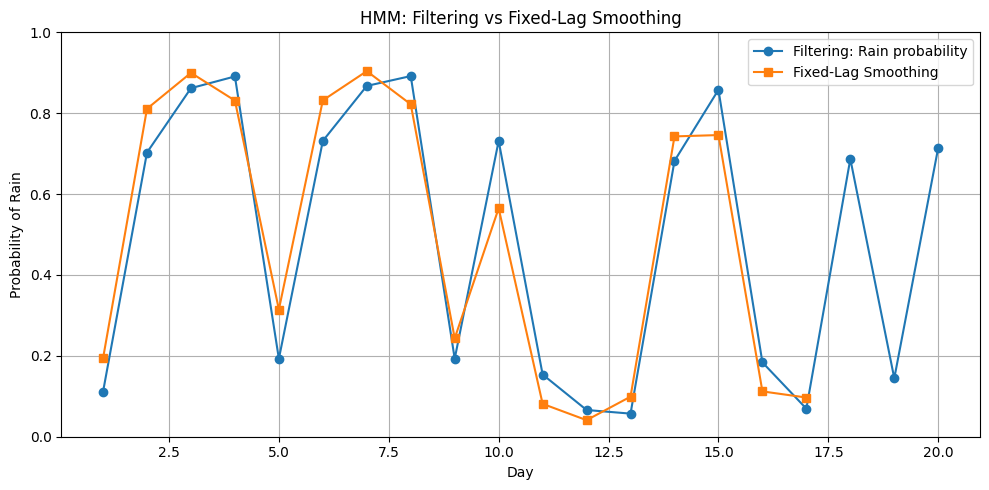

In [8]:
import numpy as np
import matplotlib.pyplot as plt

# Transition probabilities between hidden states:
# State 0 = Rain, State 1 = No Rain
T = np.array([
    [0.7, 0.3],
    [0.3, 0.7]
])

# Observation likelihoods:
# O[1] = probability of observing 1 in each hidden state
# O[0] = probability of observing 0 in each hidden state
O = {
    1: np.array([0.9, 0.2]),
    0: np.array([0.1, 0.8])
}

N, lag = 20, 3
rng = np.random.default_rng(12)

hidden = []
observations = []
state = 0

# Generate hidden states and observations.
for i in range(N):
    state = rng.choice(2, p=T[state])
    observation = int(rng.random() < O[1][state])
    hidden.append(state)
    observations.append(observation)

print("Observations:", observations)

# Forward filtering.
F = np.array([0.5, 0.5])
filtered = []

for observation in observations:
    F = O[observation] * (T.T @ F)
    F = F / F.sum()
    filtered.append(F.copy())

filtered = np.array(filtered)

# Fixed-lag smoothing.
smoothed = []

for k in range(N - lag):
    B = np.ones(2)

    for i in range(k + lag, k, -1):
        B = T @ (O[observations[i]] * B)

    S = filtered[k] * B
    S = S / S.sum()
    smoothed.append(S)

smoothed = np.array(smoothed)

# Plot the probability of Rain (hidden state 0).
days = np.arange(1, N + 1)

plt.figure(figsize=(10, 5))
plt.plot(days, filtered[:, 0], "o-", label="Filtering: Rain probability")
plt.plot(
    days[:len(smoothed)],
    smoothed[:, 0],
    "s-",
    label="Fixed-Lag Smoothing"
)
plt.xlabel("Day")
plt.ylabel("Probability of Rain")
plt.title("HMM: Filtering vs Fixed-Lag Smoothing")
plt.ylim(0, 1)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

## 8. Quick Revision Cheat Sheet

| Algorithm | Core concept / key structure |
|---|---|
| BFS | Queue — level-by-level exploration |
| DFS | Stack — go deep along a branch first |
| UCS | Priority queue — lowest actual path cost `g(n)` |
| A* Search | Priority queue — actual cost + heuristic: `f(n) = g(n) + h(n)` |
| Bayesian Enumeration | Enumerate state possibilities and normalize |
| Short Bayesian Calculation | Multiply joint probabilities and sum over hidden possibilities |
| HMM Filtering | Forward update using observations up to the current time |
| HMM Fixed-Lag Smoothing | Revise an earlier estimate using a limited number of later observations |

### Important formulas

**Joint probability (independent events):**

\[
P(A\cap B)=P(A)P(B)
\]

**A* evaluation function:**

\[
f(n)=g(n)+h(n)
\]

**Bayesian network joint distribution:**

\[
P(X_1,\ldots,X_n)=\prod_i P(X_i\mid Parents(X_i))
\]

**Filtering:**

\[
P(X_t\mid e_{1:t})
\]

**Fixed-lag smoothing:**

\[
P(X_k\mid e_{1:k+d})
\]